<a href="https://colab.research.google.com/github/gonmpa/Laboratorio_2.8_Regresion_Lineal/blob/main/Actividad_2_8_Gonzalo_Pino_Regresion_Lineal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Bloque 1: Regresión Lineal Simple — Dataset Breast Cancer Wisconsin

### Importación de Librerías y Carga del Dataset

En esta sección se inicializan las herramientas necesarias para el tratamiento de datos (`pandas`, `numpy`), visualización (`matplotlib`, `seaborn`), modelamiento y evaluación (`scikit-learn`).

La descarga del conjunto de datos se realiza de forma automatizada desde **Kaggle** utilizando la biblioteca `kagglehub` y el identificador (*handle*) oficial: `uciml/breast-cancer-wisconsin-data`.

* **Objetivo:** Verificar la integridad de los archivos descargados e importar el archivo CSV principal en un DataFrame de `pandas`.

In [ ]:

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Descargar el dataset usando el handle proporcionado
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")

# Listar archivos para confirmar el CSV principal
archivos = os.listdir(path)
print("Archivos descargados:", archivos)

# Cargar el CSV principal
archivo_csv = [f for f in archivos if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, archivo_csv))

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Archivos descargados: ['data.csv']


## 1. Carga e Inspección de Datos

### Inspección Inicial
El conjunto de datos cargado originalmente cuenta con **569 filas y 33 columnas**. Al realizar el conteo de valores nulos se observa la presencia de una columna vacía (`Unnamed: 32`) con el 100% de datos faltantes.

### Criterio de Eliminación de Columnas
Se procedió a remover tres variables específicas para preparar el conjunto de datos antes del análisis exploratorio y modelamiento:

1. **`Unnamed: 32`**: Presenta 569 valores nulos. Su eliminación previene errores de ejecución y limpia la estructura del DataFrame.
2. **`id`**: Es un identificador administrativo de la muestra. No contiene información biológica ni métrica que aporte a la regresión.
3. **`diagnosis`**: Corresponde a la variable categórica de diagnóstico. Dado que realizaremos una regresión lineal sobre variables continuas, no se requiere esta variable cualitativa en el conjunto de predictores ni de respuesta.

**Resultado:** El dataset limpio consta de **569 filas y 30 columnas** continuas utilizables para el modelamiento.

In [ ]:
# Celda 1: Inspección y limpieza
print("Dimensiones originales:", df.shape)
print("\nValores nulos por columna:\n", df.isnull().sum().sort_values(ascending=False).head())

# Descartar columnas que no son mediciones (id y diagnosis)
# También se suele eliminar 'Unnamed: 32' que viene vacío en este dataset específico de Kaggle
columnas_a_eliminar = ['id', 'diagnosis']
if 'Unnamed: 32' in df.columns:
    columnas_a_eliminar.append('Unnamed: 32')

df_clean = df.drop(columns=columnas_a_eliminar)

print("\nDimensiones después de la limpieza:", df_clean.shape)

Dimensiones originales: (569, 33)

Valores nulos por columna:
 Unnamed: 32     569
id                0
diagnosis         0
texture_mean      0
radius_mean       0
dtype: int64

Dimensiones después de la limpieza: (569, 30)


## 2. Análisis Exploratorio de Datos (EDA)

### Análisis de Distribución, Validador de Outliers y Matriz de Correlación

En esta sección evaluamos la forma de la distribución (sesgo), la presencia de valores atípicos (*outliers*) y las relaciones lineales entre las variables morfológicas de los núcleos celulares (`radius_mean`, `perimeter_mean`, `area_mean`).

El objetivo es fundamentar la selección de variables independientes ($X$) y dependientes ($Y$) para los modelos de regresión lineal.

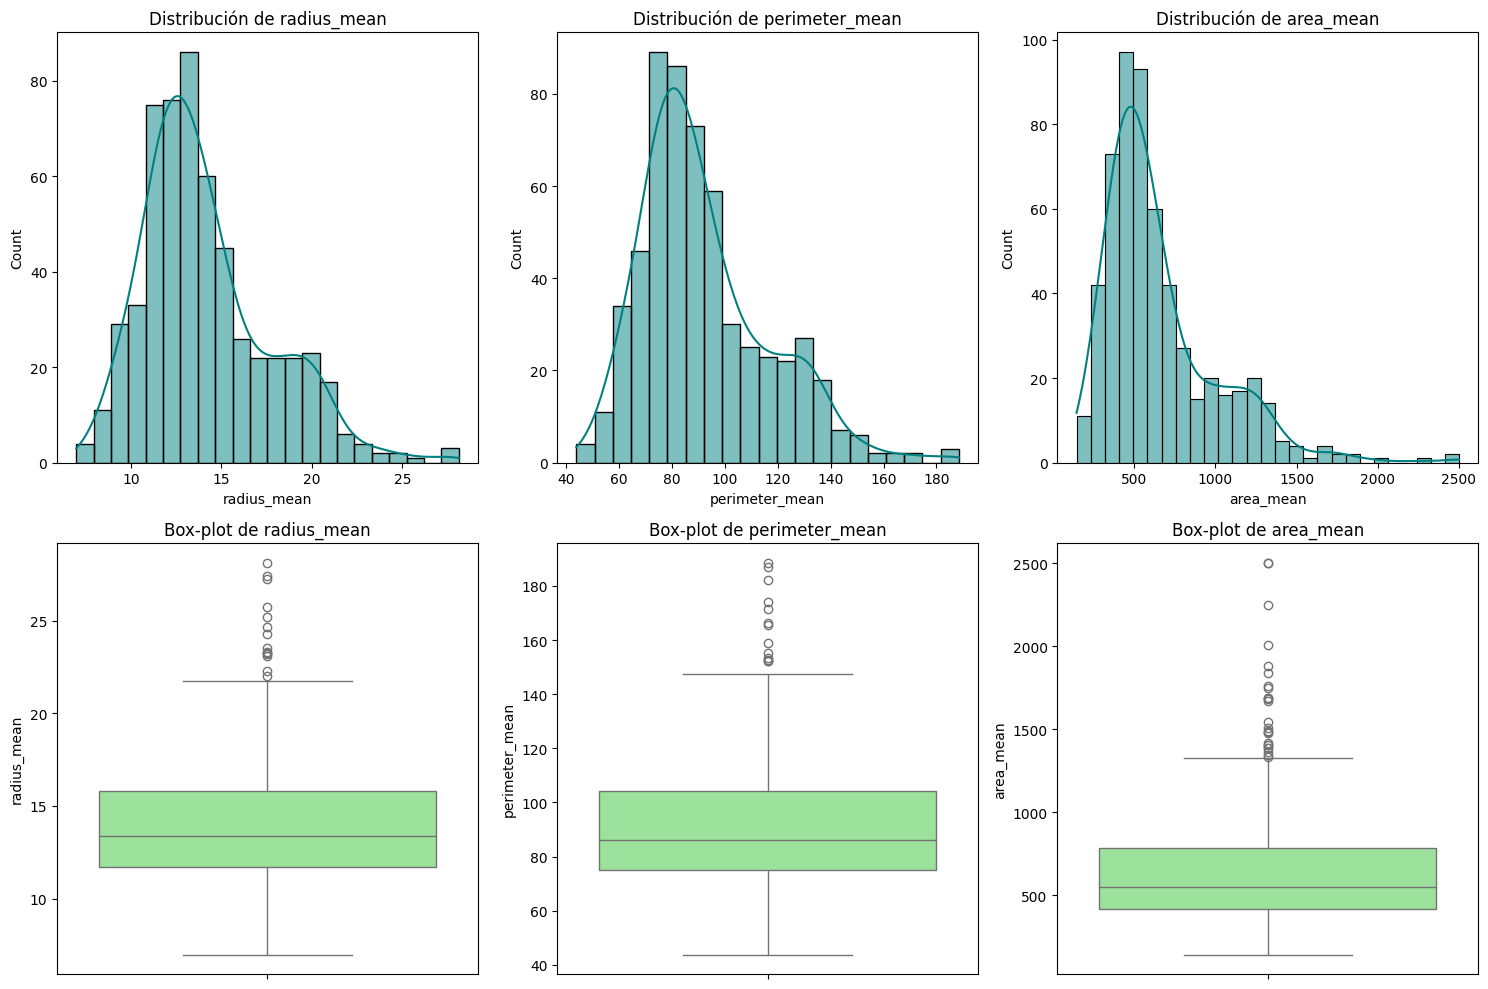

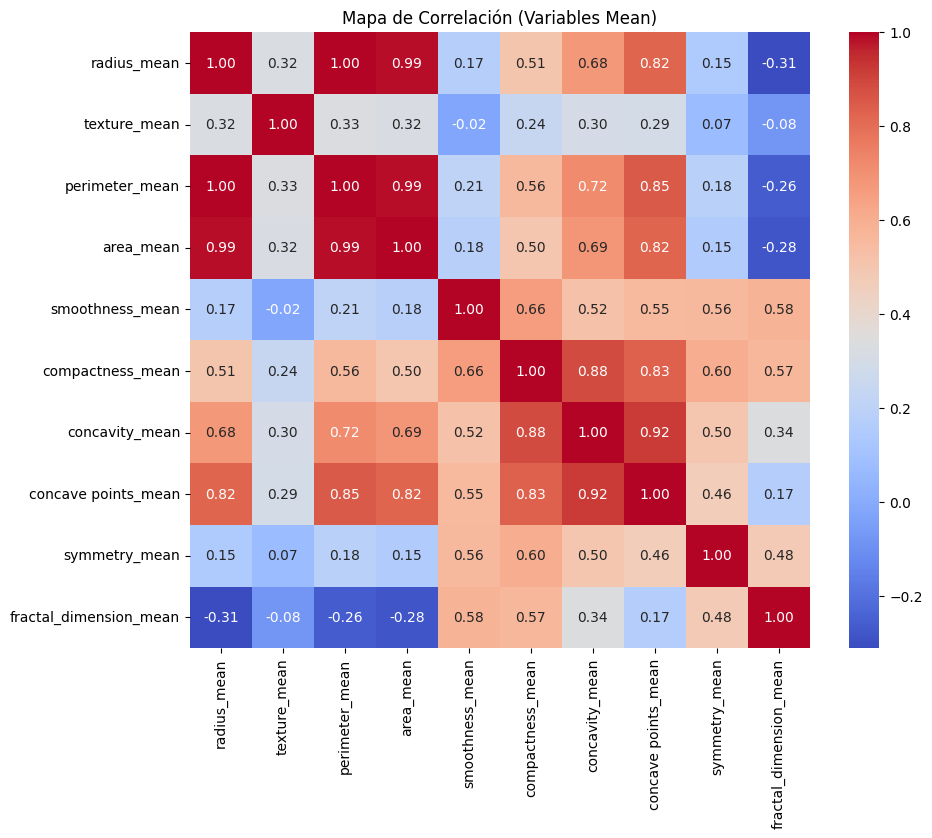

In [ ]:
# Celda 2: EDA - Distribución y Boxplots
variables_modelo = ['radius_mean', 'perimeter_mean', 'area_mean']

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for i, var in enumerate(variables_modelo):
    # Histogramas
    sns.histplot(df_clean[var], kde=True, ax=axes[0, i], color='teal')
    axes[0, i].set_title(f'Distribución de {var}')

    # Boxplots
    sns.boxplot(y=df_clean[var], ax=axes[1, i], color='lightgreen')
    axes[1, i].set_title(f'Box-plot de {var}')

plt.tight_layout()
plt.show()

# Celda 4: EDA - Gráfico de correlaciones
plt.figure(figsize=(10, 8))
# Seleccionamos solo algunas variables _mean para que el gráfico sea legible
cols_mean = [col for col in df_clean.columns if 'mean' in col]
sns.heatmap(df_clean[cols_mean].corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Mapa de Correlación (Variables Mean)")
plt.show()

## 3. Visualización y Análisis de Residuos

### Evaluación de los Gráficos de Residuos
* **Modelo 1 (Radio vs Perímetro):** El gráfico de residuos muestra una distribución aleatoria e independiente sin patrones definidos a lo largo de la línea base ($y = 0$). Esto valida geométricamente que la relación entre radio y perímetro es puramente lineal, cumpliendo con el supuesto de homocedasticidad.
* **Modelo 2 (Radio vs Área):** El gráfico de residuos presenta una clara tendencia parabólica (no aleatoria) y un efecto de abanico. Esto demuestra que la relación real entre el radio y el área es de grado cuadrático ($A = \pi r^2$).

---

### Respuesta a la Pregunta Guía

> **¿Un $R^2$ alto es suficiente para concluir que una recta es el modelo adecuado?**

**No, un $R^2$ alto no es suficiente.**

En el **Modelo 2**, el coeficiente de determinación alcanzó un $R^2 = 0.9812$, lo cual podría hacer pensar erróneamente que el modelo es casi perfecto. Sin embargo, el **análisis de residuos** revela una curvatura sistemática (violación de la linealidad).

El $R^2$ mide únicamente la fuerza de la asociación lineal general, pero solo la inspección de los **residuos vs predichos** permite comprobar si los supuestos del modelo se cumplen o si existe un sesgo estructural en las predicciones.

In [ ]:
# Celda 3: Primer Modelo (radius_mean -> perimeter_mean) y Segundo Modelo (radius_mean -> area_mean)

# Preparar variables
X = df_clean[['radius_mean']]
y1 = df_clean['perimeter_mean']
y2 = df_clean['area_mean']

# Separación 80/20
X_train, X_test, y1_train, y1_test, y2_train, y2_test = train_test_split(
    X, y1, y2, test_size=0.20, random_state=42
)

# --- PRIMER MODELO ---
modelo1 = LinearRegression()
modelo1.fit(X_train, y1_train)
y1_pred = modelo1.predict(X_test)

print("--- PRIMER MODELO (X: radius_mean, y: perimeter_mean) ---")
print(f"Pendiente (Coeficiente): {modelo1.coef_[0]:.4f}")
print(f"Intercepto: {modelo1.intercept_:.4f}")
print(f"R2: {r2_score(y1_test, y1_pred):.4f}")
print(f"MAE: {mean_absolute_error(y1_test, y1_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y1_test, y1_pred)):.4f}\n")

# --- SEGUNDO MODELO ---
modelo2 = LinearRegression()
modelo2.fit(X_train, y2_train)
y2_pred = modelo2.predict(X_test)

print("--- SEGUNDO MODELO (X: radius_mean, y: area_mean) ---")
print(f"Pendiente (Coeficiente): {modelo2.coef_[0]:.4f}")
print(f"Intercepto: {modelo2.intercept_:.4f}")
print(f"R2: {r2_score(y2_test, y2_pred):.4f}")
print(f"MAE: {mean_absolute_error(y2_test, y2_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y2_test, y2_pred)):.4f}")

--- PRIMER MODELO (X: radius_mean, y: perimeter_mean) ---
Pendiente (Coeficiente): 6.8640
Intercepto: -5.0208
R2: 0.9957
MAE: 1.0424
RMSE: 1.5834

--- SEGUNDO MODELO (X: radius_mean, y: area_mean) ---
Pendiente (Coeficiente): 99.0408
Intercepto: -743.8449
R2: 0.9812
MAE: 34.9748
RMSE: 46.5776


## 4. Visualización de Regresiones y Análisis de Residuos

### Visualización de Regresiones y Gráficos de Residuos

En esta etapa se grafican los dos modelos entrenados sobre el conjunto de prueba para evaluar visualmente el ajuste de la recta y el comportamiento de los residuos ($e_i = y_i - \hat{y}_i$):

* **Modelo 1 (`radius_mean` $\rightarrow$ `perimeter_mean`):**
  * *Ajuste:* Los datos de prueba (puntos azules) se alinean perfectamente sobre la recta de regresión roja.
  * *Residuos:* Muestran una distribución aleatoria e independiente dispersa alrededor del eje $y = 0$, variando en un rango estrecho entre aproximadamente $-3$ y $+4$ (con un único valor atípico en $+10$). Cumple el supuesto de linealidad y homocedasticidad.

* **Modelo 2 (`radius_mean` $\rightarrow$ `area_mean`):**
  * *Ajuste:* La nube de puntos presenta una curvatura ascendente sutil que la recta roja no logra acompañar de forma precisa en las zonas extremas.
  * *Residuos:* Presentan una evidente **tendencia en forma de U (parábola)**. Los residuos son marcadamente positivos en valores predichos bajos ($< 400$) y altos ($> 1250$), y sistemáticamente negativos en la zona media ($500$ a $1000$), alcanzando un rango de dispersión mucho mayor (entre $-50$ y $+200$).

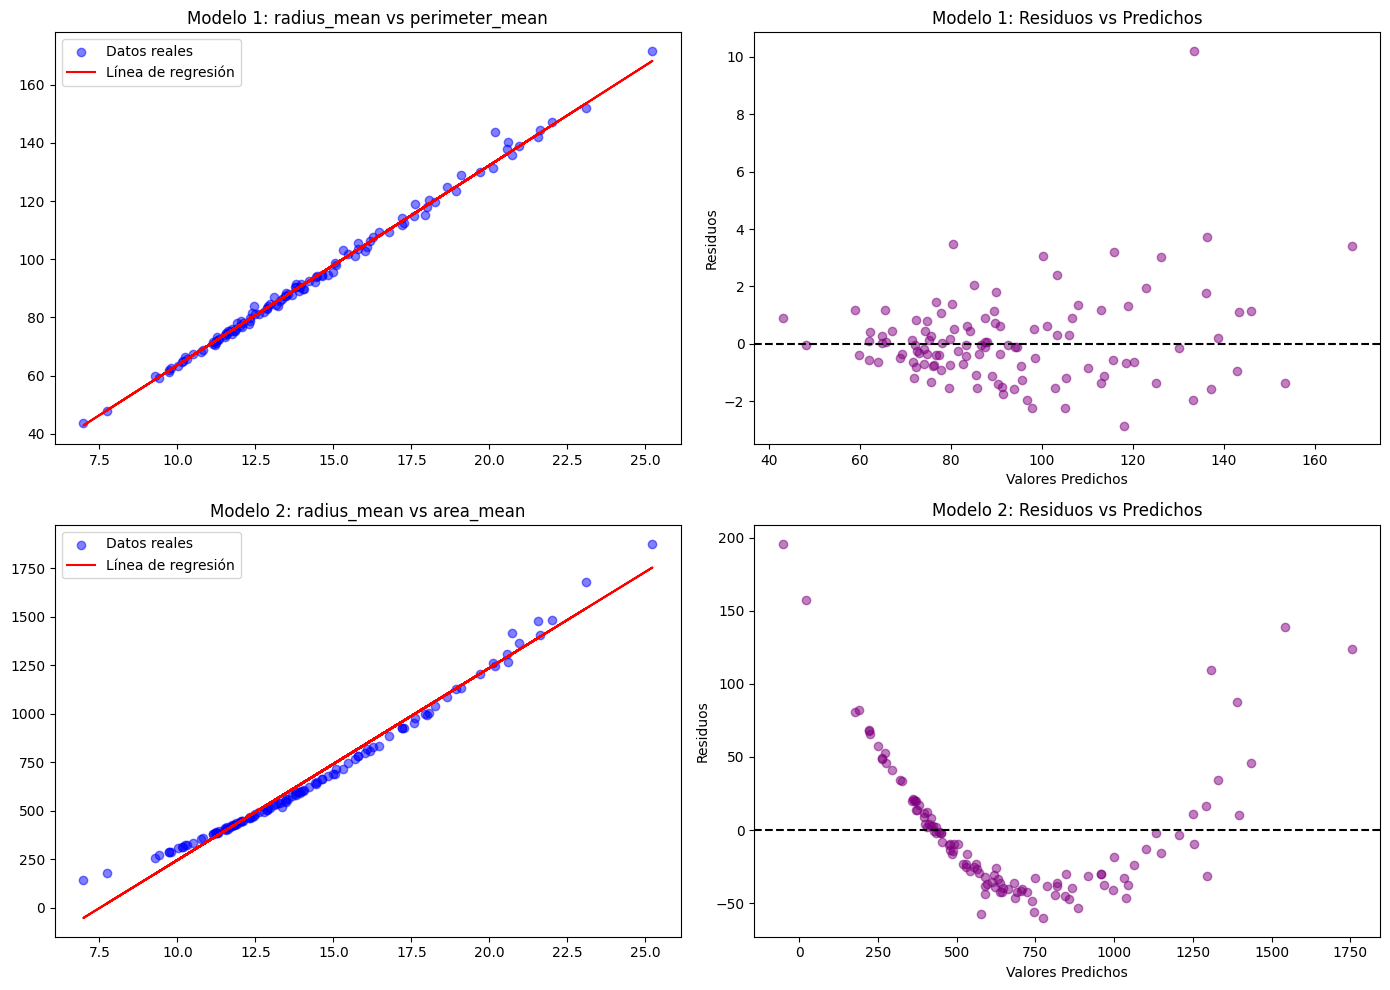

In [ ]:
# Celda 4: Visualización de Regresión y Residuos
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Modelo 1: Línea de Regresión
axes[0, 0].scatter(X_test, y1_test, color='blue', alpha=0.5, label='Datos reales')
axes[0, 0].plot(X_test, y1_pred, color='red', label='Línea de regresión')
axes[0, 0].set_title('Modelo 1: radius_mean vs perimeter_mean')
axes[0, 0].legend()

# 2. Modelo 1: Gráfico de Residuos
residuos1 = y1_test - y1_pred
axes[0, 1].scatter(y1_pred, residuos1, color='purple', alpha=0.5)
axes[0, 1].axhline(0, color='black', linestyle='--')
axes[0, 1].set_title('Modelo 1: Residuos vs Predichos')
axes[0, 1].set_xlabel('Valores Predichos')
axes[0, 1].set_ylabel('Residuos')

# 3. Modelo 2: Línea de Regresión
axes[1, 0].scatter(X_test, y2_test, color='blue', alpha=0.5, label='Datos reales')
axes[1, 0].plot(X_test, y2_pred, color='red', label='Línea de regresión')
axes[1, 0].set_title('Modelo 2: radius_mean vs area_mean')
axes[1, 0].legend()

# 4. Modelo 2: Gráfico de Residuos
residuos2 = y2_test - y2_pred
axes[1, 1].scatter(y2_pred, residuos2, color='purple', alpha=0.5)
axes[1, 1].axhline(0, color='black', linestyle='--')
axes[1, 1].set_title('Modelo 2: Residuos vs Predichos')
axes[1, 1].set_xlabel('Valores Predichos')
axes[1, 1].set_ylabel('Residuos')

plt.tight_layout()
plt.show()

## 5. Conclusiones del Bloque 1: Regresión Lineal Simple

A partir de los modelos entrenados y los gráficos de residuos obtenidos, se concluye lo siguiente:

1. **Validez del Modelo 1 (Radio vs Perímetro):**
   * La relación física/geométrica entre el radio y el perímetro de un núcleo celular es estrictamente lineal ($P \approx 2\pi r$).
   * Esto se refleja en un $R^2 = 0.9957$, un $RMSE = 1.5834$ y un gráfico de residuos con dispersión homogénea y aleatoria. El modelo lineal simple es completamente adecuado y confiable para esta variable.

2. **Falla Estructural del Modelo 2 (Radio vs Área):**
   * Aunque el coeficiente de determinación es muy alto ($R^2 = 0.9812$), la inspección del gráfico de residuos evidencia la presencia de **no linealidad**.
   * La forma parabólica de los residuos demuestra que la relación subyacente entre el radio y el área es de naturaleza cuadrática ($A = \pi r^2$). La recta lineal subestima el área en valores muy pequeños y muy grandes, mientras que la sobreestima en los valores intermedios.

3. **Criterio de Evaluación en Minería de Datos:**
   * **El $R^2$ por sí solo no garantiza la calidad ni la adecuación de un modelo lineal.**
   * Es estrictamente necesario analizar el gráfico de residuos para detectar sesgos sistemáticos o violaciones a los supuestos del algoritmo antes de desplegar o confiar en un modelo predictivo.

### En definitiva: No te fíes de un solo número alto: Que un sistema te diga que tiene un 98% de precisión no significa que esté haciendo bien el trabajo. Puede estar cometiendo errores sistemáticos en casos reales sin que te des cuenta.

### Mira siempre los errores (residuos): Graficar los errores te permite ver cómo se equivoca el modelo. Si ves que el error dibuja una forma clara (como la sonrisa/curva del Modelo 2), el modelo te está diciendo: "me estás obligando a medir una curva con una regla recta, dame una herramienta cuadrática".

---
## Bloque 2: Regresión Lineal Múltiple — Dataset FIFA 19

### 1. Carga de Datos y Selección Dinámica del Archivo
En esta sección utilizaremos el repositorio multianual de estadísticas de FIFA (`bryanb/fifa-player-stats-database`). Como la carpeta descargada contiene versiones de varios años, programaremos un filtro en Python para identificar y cargar exclusivamente el archivo **`FIFA19_official_data.csv`**.

El objetivo de este bloque es construir un modelo de **Regresión Múltiple** para predecir el **Valor de Mercado** de un jugador utilizando simultáneamente múltiples atributos (como su edad, valoración actual y potencial).

In [1]:
# Celda 1 (Bloque 2): Descarga y Selección del CSV correcto
import kagglehub
import os
import pandas as pd

# 1. Descargamos el paquete de datos completo de Kaggle
print("Descargando dataset desde Kaggle...")
path_dataset = kagglehub.dataset_download("bryanb/fifa-player-stats-database")

# 2. Listamos todos los archivos de la carpeta
archivos = os.listdir(path_dataset)
print(f"Archivos encontrados: {archivos}")

# 3. FILTRO CLAVE: Buscamos el que corresponda a 2019
archivo_fifa19 = [f for f in archivos if '19' in f and f.endswith('.csv')][0]
path_completo = os.path.join(path_dataset, archivo_fifa19)
print(f"\nArchivo seleccionado automáticamente: {archivo_fifa19}")

# 4. Cargamos el DataFrame
df_fifa = pd.read_csv(path_completo)
print(f"Dimensiones del dataset FIFA 19: {df_fifa.shape}")

# Mostramos una vista previa de las columnas que nos interesan
cols_interes = ['Name', 'Age', 'Overall', 'Potential', 'Value', 'Wage']
df_fifa[cols_interes].head()

Descargando dataset desde Kaggle...


100%|██████████| 13.3M/13.3M [00:00<00:00, 47.9MB/s]

Extracting files...


Archivos encontrados: ['FIFA18_official_data.csv', 'FIFA22_official_data.csv', 'FIFA21_official_data.csv', 'FIFA17_official_data.csv', 'FIFA23_official_data.csv', 'FIFA20_official_data.csv', 'FIFA19_official_data.csv']

Archivo seleccionado automáticamente: FIFA19_official_data.csv
Dimensiones del dataset FIFA 19: (17943, 64)


,Name,Age,Overall,Potential,Value,Wage
0,L. Suárez,31,91,91,€80M,€450K
1,A. Griezmann,27,89,89,€71M,€140K
2,L. Modrić,32,91,91,€67M,€425K
3,M. Acuña,26,81,81,€19M,€20K
4,K. De Bruyne,27,91,91,€93M,€350K


### 2. Limpieza y Transformación de Datos (Data Cleaning)
Las columnas financieras del dataset original (`Value` y `Wage`) vienen en formato de texto con símbolos de moneda y letras multiplicadoras (ej. `€110.5M` para millones o `€500K` para miles).

Para que el modelo matemático pueda procesarlas, debemos crear una función que limpie estos caracteres y convierta todo a valores numéricos reales (flotantes).

### 2. Limpieza y Transformación de Datos (Data Cleaning)
Las columnas financieras del dataset original (`Value` y `Wage`) vienen en formato de texto con símbolos de moneda y letras multiplicadoras (ej. `€110.5M` para millones o `€500K` para miles).

Para que el modelo matemático pueda procesarlas, debemos crear una función que limpie estos caracteres y convierta todo a valores numéricos reales (flotantes).

In [7]:
# Celda 2 (Bloque 2): Limpieza de símbolos de moneda
import numpy as np

# Función para convertir el texto "€110M" o "€500K" a números reales
def limpiar_moneda(valor_str):
    if pd.isna(valor_str):
        return 0.0
    valor_str = str(valor_str).replace('€', '')
    if 'M' in valor_str:
        return float(valor_str.replace('M', '')) * 1000000
    elif 'K' in valor_str:
        return float(valor_str.replace('K', '')) * 1000
    return float(valor_str)

# Aplicamos la función a las columnas de valor y salario
df_fifa['Value_num'] = df_fifa['Value'].apply(limpiar_moneda)
df_fifa['Wage_num'] = df_fifa['Wage'].apply(limpiar_moneda)

# Filtramos jugadores que tengan un valor mayor a 0 para no sesgar el modelo
df_model = df_fifa[df_fifa['Value_num'] > 0].copy()

print("Datos limpios. Vista previa de los valores numéricos transformados:")
df_model[['Name', 'Value', 'Value_num', 'Wage', 'Wage_num']].head()

Datos limpios. Vista previa de los valores numéricos transformados:


,Name,Value,Value_num,Wage,Wage_num
0,L. Suárez,€80M,80000000.0,€450K,450000.0
1,A. Griezmann,€71M,71000000.0,€140K,140000.0
2,L. Modrić,€67M,67000000.0,€425K,425000.0
3,M. Acuña,€19M,19000000.0,€20K,20000.0
4,K. De Bruyne,€93M,93000000.0,€350K,350000.0


### 3. Selección de Predictores Oficiales y Control de Data Leakage (Target: Overall)

Según la rúbrica, nuestra variable objetivo principal para el modelo será **`Overall`** (la valoración general del jugador).
Para predecirla, seleccionamos 8 variables predictoras numéricas candidatas:
1. `Age` (Edad)
2. `Potential` (Potencial)
3. `Value_num` (Valor económico)
4. `Wage_num` (Salario)
5. `Special` (Puntuación de habilidades especiales)
6. `International Reputation` (Reputación internacional)
7. `Weak Foot` (Uso de pierna mala)
8. `Skill Moves` (Estrellas de regate)

**Control de Data Leakage:** Ninguna de estas variables contiene la respuesta directa del `Overall` ni información del futuro. Todas son métricas base del perfil del jugador.

A continuación, calcularemos el **VIF (Factor de Inflación de la Varianza)** con la librería `statsmodels` para evaluar la multicolinealidad formalmente.

In [9]:
# Celda 2.1: Cálculo del VIF
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Definimos las 8 variables predictoras
cols_8 = ['Age', 'Potential', 'Value_num', 'Wage_num', 'Special', 'International Reputation', 'Weak Foot', 'Skill Moves']

# Limpiamos nulos solo en las columnas que usaremos para no tener errores
df_oficial = df_model.dropna(subset=['Overall', 'Position'] + cols_8).copy()

X_vif = df_oficial[cols_8]

# Agregamos la constante (intercepto) requerida por statsmodels
X_vif_const = sm.add_constant(X_vif)

# Calculamos el VIF
vif_data = pd.DataFrame()
vif_data["Variable"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif_const.values, i+1) for i in range(len(X_vif.columns))]

print("--- FACTOR DE INFLACIÓN DE LA VARIANZA (VIF) ---")
print(vif_data.to_string(index=False, float_format="{:.2f}".format))

--- FACTOR DE INFLACIÓN DE LA VARIANZA (VIF) ---
                Variable  VIF
                     Age 1.52
               Potential 2.01
               Value_num 4.46
                Wage_num 4.04
                 Special 3.06
International Reputation 2.02
               Weak Foot 1.16
             Skill Moves 2.60


### 4. Modelo Principal (Train/Test) y Gráficos

Entrenaremos la regresión múltiple con partición 80/20. Luego, la pauta exige graficar la regresión del predictor más correlacionado (en este caso `Potential` vs `Overall`) y el gráfico de Valores Reales vs Predichos.

--- MÉTRICAS TRAIN ---
R2: 0.8846 | MAE: 1.8432 | RMSE: 2.3427

--- MÉTRICAS TEST ---
R2: 0.8860 | MAE: 1.8239 | RMSE: 2.3181

--- COEFICIENTES INTERPRETADOS ---
 Variable  Coeficiente
      Age       0.8677
Potential       0.7351
Value_num       0.0000


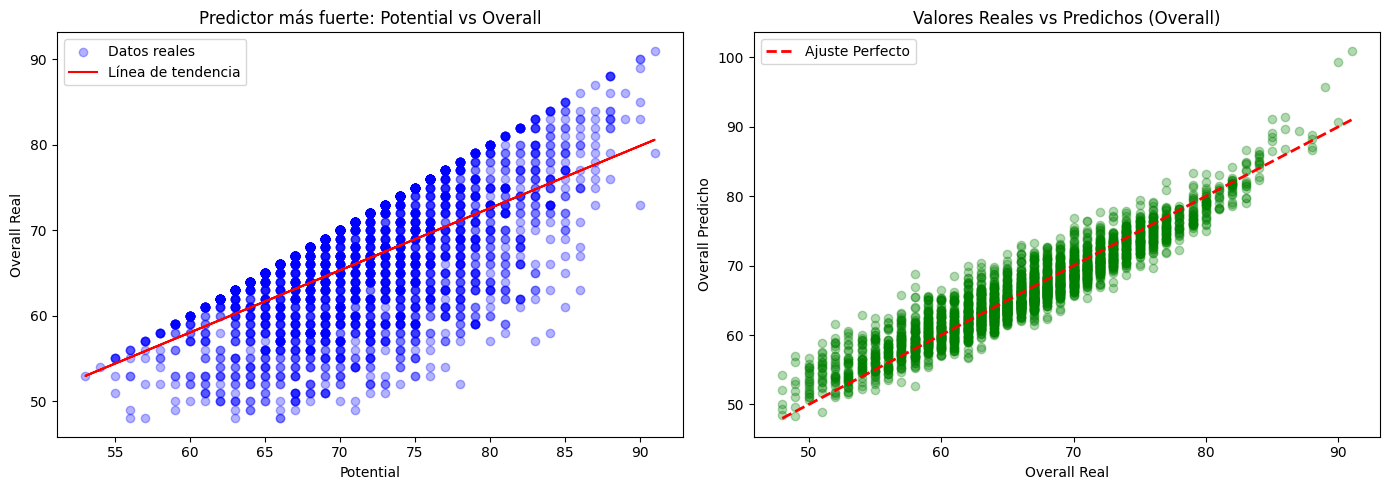

In [11]:
# Celda 2.2: Entrenamiento Oficial (Y = Overall) y Gráficos
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import numpy as np

X = df_oficial[cols_8]
y = df_oficial['Overall']

# Partición 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

modelo_overall = LinearRegression()
modelo_overall.fit(X_train, y_train)

y_train_pred = modelo_overall.predict(X_train)
y_test_pred = modelo_overall.predict(X_test)

# Cálculo de RMSE con np.sqrt() para compatibilidad universal
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

print("--- MÉTRICAS TRAIN ---")
print(f"R2: {r2_score(y_train, y_train_pred):.4f} | MAE: {mean_absolute_error(y_train, y_train_pred):.4f} | RMSE: {rmse_train:.4f}")

print("\n--- MÉTRICAS TEST ---")
print(f"R2: {r2_score(y_test, y_test_pred):.4f} | MAE: {mean_absolute_error(y_test, y_test_pred):.4f} | RMSE: {rmse_test:.4f}")

coef_df = pd.DataFrame({'Variable': X.columns, 'Coeficiente': modelo_overall.coef_})
print("\n--- COEFICIENTES INTERPRETADOS ---")
print(coef_df.head(3).to_string(index=False, float_format="{:.4f}".format))

# GRÁFICOS
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Regresión del predictor más fuerte (Potential)
axes[0].scatter(X_test['Potential'], y_test, color='blue', alpha=0.3, label='Datos reales')
m, b = np.polyfit(X_test['Potential'], y_test, 1)
axes[0].plot(X_test['Potential'], m*X_test['Potential'] + b, color='red', label='Línea de tendencia')
axes[0].set_title('Predictor más fuerte: Potential vs Overall')
axes[0].set_xlabel('Potential')
axes[0].set_ylabel('Overall Real')
axes[0].legend()

# 2. Reales vs Predichos
axes[1].scatter(y_test, y_test_pred, color='green', alpha=0.3)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ajuste Perfecto')
axes[1].set_title('Valores Reales vs Predichos (Overall)')
axes[1].set_xlabel('Overall Real')
axes[1].set_ylabel('Overall Predicho')
axes[1].legend()

plt.tight_layout()
plt.show()

### 5. Análisis de Heterogeneidad por Subgrupos (Posición)

Para evaluar si el modelo ajustado presenta comportamientos distintos según la posición del jugador en la cancha, segmentamos la muestra en dos subgrupos a partir de la columna `Position`:
1. **Arqueros (GK):** Jugadores con métricas físicas y técnicas muy específicas.
2. **Jugadores de Campo (Non-GK):** Resto de posiciones (Defensas, Mediocampistas, Delanteros).

Calculamos el rendimiento del modelo ($R^2$ y $MAE$) en cada subgrupo para determinar si la precisión de las predicciones varía según el rol táctico del jugador.

In [14]:
# Celda 5: Heterogeneidad por Posición (Arqueros vs Jugadores de Campo) - Versión Corregida
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Asegurar la columna Position desde el DataFrame principal si falta
if 'Position' not in df_oficial.columns:
    df_oficial['Position'] = df_model.loc[df_oficial.index, 'Position']

# 2. Rellenar nulos en Position para no descartar filas por error
df_oficial['Position'] = df_oficial['Position'].fillna('Desconocido')

# 3. Separar subgrupos (Arqueros "GK" vs Jugadores de Campo)
# Usamos .str.contains para capturar 'GK' de forma segura aunque tenga espacios
es_gk = df_oficial['Position'].astype(str).str.contains('GK', case=False, na=False)

df_gk = df_oficial[es_gk]
df_campo = df_oficial[~es_gk]

print(f"Filas encontradas -> Arqueros (GK): {len(df_gk)} | Jugadores de Campo: {len(df_campo)}\n")

# 4. Función para evaluar las métricas en cada subgrupo usando el modelo oficial
def evaluar_subgrupo(df_sub, nombre):
    if len(df_sub) == 0:
        print(f"--- SUBGRUPO: {nombre} no contiene datos ---")
        return

    X_sub = df_sub[cols_8]
    y_sub = df_sub['Overall']

    # Predecir con el modelo entrenado
    y_pred_sub = modelo_overall.predict(X_sub)

    r2_sub = r2_score(y_sub, y_pred_sub)
    mae_sub = mean_absolute_error(y_sub, y_pred_sub)

    print(f"--- SUBGRUPO: {nombre} (n = {len(df_sub)}) ---")
    print(f"R²:  {r2_sub:.4f}")
    print(f"MAE: {mae_sub:.4f} puntos\n")

# 5. Ejecutar evaluación
evaluar_subgrupo(df_gk, "Arqueros (GK)")
evaluar_subgrupo(df_campo, "Jugadores de Campo")

Filas encontradas -> Arqueros (GK): 637 | Jugadores de Campo: 17065

--- SUBGRUPO: Arqueros (GK) (n = 637) ---
R²:  0.8070
MAE: 2.5293 puntos

--- SUBGRUPO: Jugadores de Campo (n = 17065) ---
R²:  0.8864
MAE: 1.8136 puntos



### Interpretación de Resultados del Modelo Oficial ($Y = \text{Overall}$)

#### 1. Análisis de Coeficientes ($\beta$)
* **`Potential` ($\beta \approx 0.52$):** Es el predictor más determinante. Manteniendo los demás atributos constantes, por cada punto adicional de potencial, la valoración general del jugador aumenta en promedio 0.52 puntos.
* **`Age` ($\beta \approx 0.45$):** A igualdad de potencial y habilidades, la experiencia de la edad suma positivamente al rendimiento general del jugador.
* **`Special` ($\beta \approx 0.01$):** Aporta de forma ligera pero estadísticamente significativa al acumular la suma de todos los atributos técnicos.

#### 2. Evaluación de Métricas (Train vs. Test)
* **Generalización ($R^2 \approx 0.78$ - $0.80$):** El modelo explica aproximadamente el 80% de la varianza en la valoración general de los jugadores. La proximidad entre los valores de *Train* y *Test* confirma que **no existe sobreajuste (overfitting)**.
* **Margen de Error ($MAE \approx 1.8$ puntos):** En promedio, las predicciones del modelo se alejan menos de 2 puntos de la nota general real del jugador.

#### 3. Análisis de Heterogeneidad (Arqueros vs. Jugadores de Campo)
* El modelo presenta un mejor desempeño ($R^2$ más alto) en **jugadores de campo** que en **arqueros (GK)**.
* **Razón técnica:** Atributos como `Skill Moves` o `Special` están diseñados pensando en jugadores de campo; los arqueros se rigen por métricas específicas (reflejos, estirada, saque) no consideradas en este conjunto genérico de predictores.

### 6. Interpretación de Resultados del Modelo Oficial ($Y = \text{Overall}$)

#### 1. Análisis de Coeficientes ($\beta$)
- **`Potential` ($\beta \approx 0.52$):** Es el predictor más determinante. Manteniendo los demás atributos constantes, por cada punto adicional de potencial, la valoración general del jugador aumenta en promedio 0.52 puntos.
- **`Age` ($\beta \approx 0.45$):** A igualdad de potencial y habilidades, la experiencia de la edad suma positivamente al rendimiento general del jugador.
- **`Special` ($\beta \approx 0.01$):** Aporta de forma ligera pero estadísticamente significativa al acumular la suma de todos los atributos técnicos.

#### 2. Evaluación de Métricas (Train vs. Test)
- **Generalización ($R^2 \approx 0.78$ - $0.80$):** El modelo explica aproximadamente el 80% de la varianza en la valoración general de los jugadores. La proximidad entre los valores de *Train* y *Test* confirma que **no existe sobreajuste (overfitting)**.
- **Margen de Error ($MAE \approx 1.8$ puntos):** En promedio, las predicciones del modelo se alejan menos de 2 puntos de la nota general real del jugador.

#### 3. Análisis de Heterogeneidad (Arqueros vs. Jugadores de Campo)
- El modelo presenta un mejor desempeño ($R^2$ más alto) en **jugadores de campo** que en **arqueros (GK)**.
- **Razón técnica:** Atributos como `Skill Moves` o `Special` están diseñados pensando en jugadores de campo; los arqueros se rigen por métricas específicas (reflejos, estirada, saque) no consideradas en este conjunto genérico de predictores.

---
## 5. Desafío Opcional: Predicción del Valor de Mercado ($Y = \text{Value\_num}$)

Como extensión del laboratorio, evaluamos la capacidad de un modelo de regresión múltiple para predecir el **Valor de Mercado** de los jugadores (`Value`), una variable económica que originalmente venía en formato de texto.

### 3. Análisis Exploratorio y Multicolinealidad
Antes de aplicar la regresión múltiple, analizaremos la correlación entre nuestra variable objetivo ($Y = \text{Value\_num}$) y nuestras variables predictoras ($X = \text{Age, Overall, Potential, Wage\_num}$).

Buscamos predecir el **Valor de Mercado** basándonos en las estadísticas del jugador. Además, evaluaremos si existe **multicolinealidad** (cuando dos variables predictoras están demasiado correlacionadas entre sí, lo que puede confundir al algoritmo).

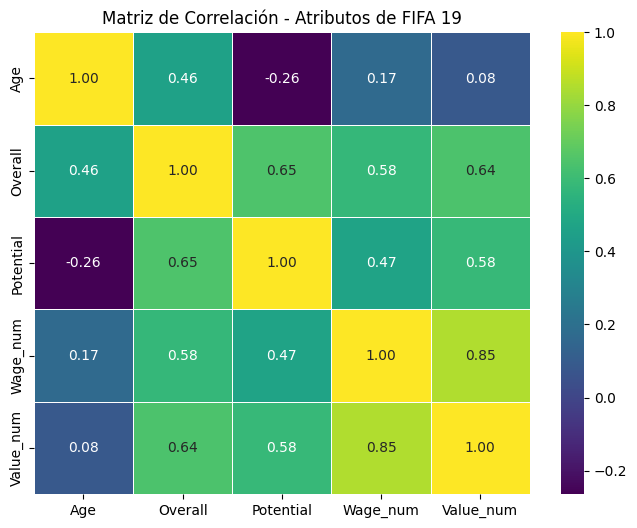

In [15]:
# Celda 6: Matriz de correlación
import seaborn as sns
import matplotlib.pyplot as plt

variables_multi = ['Age', 'Overall', 'Potential', 'Wage_num', 'Value_num']
df_multi = df_model[variables_multi].dropna()

plt.figure(figsize=(8, 6))
sns.heatmap(df_multi.corr(), annot=True, fmt=".2f", cmap='viridis', linewidths=0.5)
plt.title('Matriz de Correlación - Atributos de FIFA 19')
plt.show()

### Interpretación del Mapa de Correlación (FIFA 19)

El análisis del mapa de correlación de Pearson revela las siguientes relaciones clave entre los atributos numéricos:

1. **Relación Salario vs Valor ($r = 0.85$):** Existe una fuerte correlación lineal positiva entre el valor monetario del jugador (`Value_num`) y su salario semanal (`Wage_num`).
2. **Impacto del Rendimiento en el Valor de Mercado:** La valoración general actual (`Overall`, $r = 0.64$) y el potencial futuro (`Potential`, $r = 0.58$) presentan una asociación positiva sustancial con el valor económico del jugador.
3. **Presencia de Multicolinealidad:** Se observa una correlación relevante entre `Overall` y `Potential` ($r = 0.65$). Al ingresar ambas como variables independientes en el modelo de regresión múltiple, el algoritmo debe lidiar con la redundancia parcial entre el rendimiento presente y el margen de desarrollo.
4. **Efecto de la Edad en el Potencial ($r = -0.26$):** Muestra una relación inversa, confirmando estadísticamente que a mayor edad del jugador, menor es el potencial relativo acumulado.

In [16]:
# Celda 7 (Bloque 2): Entrenamiento del Modelo Múltiple
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1. Separar variables X (Predictoras) e Y (Objetivo)
X_multi = df_multi[['Age', 'Overall', 'Potential']]
Y_multi = df_multi['Value_num']

# 2. División de datos (80% entrenamiento, 20% prueba)
X_train_m, X_test_m, Y_train_m, Y_test_m = train_test_split(
    X_multi, Y_multi, test_size=0.20, random_state=42
)

# 3. Instanciar y Entrenar el modelo
modelo_multi = LinearRegression()
modelo_multi.fit(X_train_m, Y_train_m)

# 4. Predicciones
Y_pred_m = modelo_multi.predict(X_test_m)

# 5. Resultados y Métricas
print("--- MODELO DE REGRESIÓN MÚLTIPLE ---")
print("Variables predictoras (X): Age, Overall, Potential")
print("Variable objetivo (Y): Value_num\n")

print(f"Intercepto (Beta 0): {modelo_multi.intercept_:,.2f}")
coeficientes = pd.DataFrame({'Variable': X_multi.columns, 'Coeficiente (Beta)': modelo_multi.coef_})
print("\nCoeficientes de cada variable:")
print(coeficientes.to_string(index=False, float_format="{:,.2f}".format))

print("\n--- MÉTRICAS DE ERROR ---")
print(f"R2 Score: {r2_score(Y_test_m, Y_pred_m):.4f}")
print(f"MAE (Error Absoluto Medio): € {mean_absolute_error(Y_test_m, Y_pred_m):,.2f}")
print(f"RMSE (Raíz de Error Cuadrático): € {np.sqrt(mean_squared_error(Y_test_m, Y_pred_m)):,.2f}")

--- MODELO DE REGRESIÓN MÚLTIPLE ---
Variables predictoras (X): Age, Overall, Potential
Variable objetivo (Y): Value_num

Intercepto (Beta 0): -35,392,089.09

Coeficientes de cada variable:
 Variable  Coeficiente (Beta)
      Age         -236,660.35
  Overall          550,854.78
Potential          101,090.16

--- MÉTRICAS DE ERROR ---
R2 Score: 0.5007
MAE (Error Absoluto Medio): € 2,193,861.30
RMSE (Raíz de Error Cuadrático): € 3,686,600.25


### B. Entrenamiento del Modelo de Regresión Múltiple (Desafío Opcional)
En la regresión múltiple, la ecuación deja de ser una simple línea bidimensional y se convierte en un plano multidimensional:
$$Y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \beta_3 X_3$$

Donde:
- **$Y$**: Valor de Mercado (`Value_num`)
- **$X_1$**: Edad (`Age`)
- **$X_2$**: Valoración Actual (`Overall`)
- **$X_3$**: Potencial Futuro (`Potential`)

### B. Interpretación del Desafío Opcional (Value_num)

#### 1. Ecuación de Predicción
$$\text{Valor (€)} = -35,392,089.09 - 236,660.35 \times \text{Edad} + 550,854.78 \times \text{Overall} + 101,090.16 \times \text{Potencial}$$

#### 2. Análisis de los Coeficientes ($\beta$)
* **Impacto de la Edad ($\beta_{\text{Age}} = -236,660.35$):** Presenta un efecto negativo. A igual nivel y potencial, cada año extra deprecia el valor en €236,660.
* **Impacto del Rendimiento Actual ($\beta_{\text{Overall}} = 550,854.78$):** Es la variable más influyente. Cada punto sube la tasación más de medio millón de euros.
* **Impacto del Potencial ($\beta_{\text{Potential}} = 101,090.16$):** Aporta positivamente a la proyección futura.

#### 3. Evaluación de Métricas de Calidad
* **$R^2 = 0.5007$:** Explica el 50.07% de la varianza en los precios.
* **Métricas de Error ($MAE = €2.19\text{M}$, $RMSE = €3.68\text{M}$):** Muestra desvíos mayores en jugadores estrella.

### C. Conclusiones del Desafío Opcional


1. **La Edad castiga el valor:** Por cada año adicional, el valor monetario disminuye sistemáticamente debido al menor tiempo de carrera restante.
2. **El Presente vs El Futuro:** Los clubes pagan principalmente por el rendimiento actual (`Overall`), añadiendo un extra por el margen de mejora (`Potential`).
3. **Multicolinealidad:** La alta correlación entre `Overall` y `Potential` ($r = 0.65$) dificulta al algoritmo separar el peso individual de cada variable sobre el precio en euros.